In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Download historical data
raw = pd.read_csv("../data/raw/raw_energy_prices.csv", header=[0, 1], skiprows=[2],
                  index_col=0, parse_dates=True)
closing_prices = raw["Close"]


# 2. Calculate daily log returns
log_returns = np.log(closing_prices / closing_prices.shift(1))

# 3. Inspect missing values
print(log_returns.isna().sum())

# 4. Combine prices and returns
dataset = pd.concat(
    [closing_prices, log_returns],
    axis=1,
    keys=["Price", "Return"]
)

# 5. Remove incomplete observations
dataset = dataset.dropna()

# 6. Display the first five rows
display(dataset.head())

# 7. Save the original and processed datasets
dataset.to_csv("../data/processed/processed_energy_returns.csv")

Ticker
ICLN    1
IXC     1
dtype: int64


Price               Return          
Ticker           ICLN        IXC      ICLN       IXC
2021-01-05  27.262537  17.204540  0.021046  0.045539
2021-01-06  29.226479  17.744701  0.069562  0.030914
2021-01-07  31.097347  18.002687  0.062047  0.014434
2021-01-08  30.864655  17.938189 -0.007511 -0.003589
2021-01-11  29.822180  18.018808 -0.034359  0.004484

In [14]:
# Extract daily log returns for each ETF

icln_returns = dataset["Return"]["ICLN"]
ixc_returns = dataset["Return"]["IXC"]

# Check how many observations we have
print("ICLN observations:", len(icln_returns))
print("IXC observations:", len(ixc_returns))

# Calculate historical mean and standard deviation
mu_icln = icln_returns.mean()
sigma_icln = icln_returns.std()

print("ICLN mean:", mu_icln)
print("ICLN standard deviation:", sigma_icln)

ICLN observations: 1254
IXC observations: 1254
ICLN mean: -0.0003891856193757808
ICLN standard deviation: 0.018105925912751876


In [15]:
# Create a random number generator
rng = np.random.default_rng(67)

# Generate 10 hypothetical daily returns
simulated_returns = rng.normal(
    loc=mu_icln,
    scale=sigma_icln,
    size=10
)

print(simulated_returns)
print("Simulated mean:", simulated_returns.mean())

[-1.07719430e-02 -4.13550655e-05 -2.42147884e-03 -7.19901639e-03
  2.56016603e-02  1.48531120e-02  8.92887058e-03  1.13805024e-02
 -2.04233231e-02  1.65852067e-02]
Simulated mean: 0.003649223554587519


In [16]:
# Generate 1,000 hypothetical daily returns

rng = np.random.default_rng(67)

simulated_returns = rng.normal(
    loc=mu_icln,
    scale=sigma_icln,
    size=1000
)

print(simulated_returns[:5])

# Count from 1 to 1,000
sample_sizes = np.arange(1, 1001)

# Calculate cumulative sums
running_totals = np.cumsum(simulated_returns)

# Divide each cumulative sum by its sample size
running_means = running_totals / sample_sizes


[-1.07719430e-02 -4.13550655e-05 -2.42147884e-03 -7.19901639e-03
  2.56016603e-02]


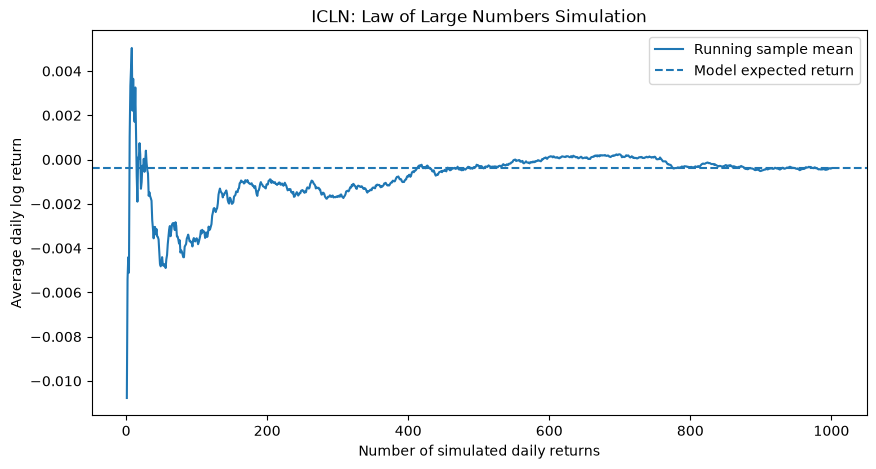

Model mean: -0.0389%
After 10 draws: 0.3649%
After 100 draws: -0.3557%
After 1000 draws: -0.0395%


In [17]:
plt.figure(figsize=(10, 5))

# Plot the running sample mean
plt.plot(
    sample_sizes,
    running_means,
    label="Running sample mean"
)

# Plot the expected return under our Normal model
plt.axhline(
    y=mu_icln,
    linestyle="--",
    label="Model expected return"
)

plt.xlabel("Number of simulated daily returns")
plt.ylabel("Average daily log return")
plt.title("ICLN: Law of Large Numbers Simulation")

plt.legend()
plt.show()

print(f"Model mean: {mu_icln:.4%}")

print(f"After 10 draws: {running_means[9]:.4%}")
print(f"After 100 draws: {running_means[99]:.4%}")
print(f"After 1000 draws: {running_means[999]:.4%}")

Hold on! What if the sequence of simulated means I get, happens to coincedentally align with the Laws of Large Numbers (LLN)? Another generated sequence might deviate further away from the theoretical mean.

Run 1: -0.0395%
Run 2: -0.0531%
Run 3: -0.1102%
Run 4: -0.0975%
Run 5: -0.0961%


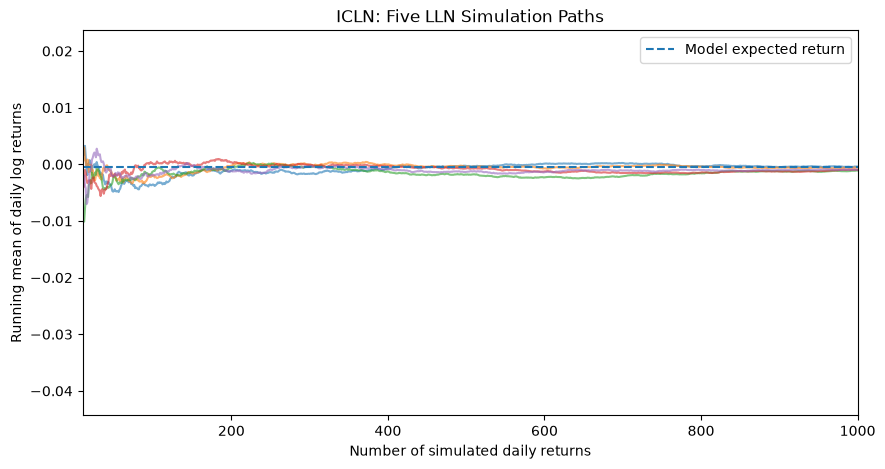

In [18]:
rng = np.random.default_rng(67)

n = 1000
sample_sizes = np.arange(1, n + 1)

plt.figure(figsize=(10, 5))

for run in range(5):

    # Generate one new sequence of returns Xi ~ N(mean, sd)
    draws = rng.normal(
        loc=mu_icln,
        scale=sigma_icln,
        size=n
    )

    # Calculate the running means
    running_means = np.cumsum(draws) / sample_sizes

    # Plot this sequence's running means
    plt.plot(sample_sizes, running_means, alpha=0.6)

    # Print the final sample mean
    print(f"Run {run + 1}: {running_means[-1]:.4%}")

# Add the theoretical target
plt.axhline(
    mu_icln,
    linestyle="--",
    label="Model expected return"
)

plt.xlim(10, 1000)
plt.xlabel("Number of simulated daily returns")
plt.ylabel("Running mean of daily log returns")
plt.title("ICLN: Five LLN Simulation Paths")
plt.legend()
plt.show()

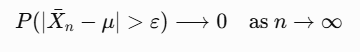

In [19]:
# Monte Carlo experiment: LLN convergence

rng = np.random.default_rng(67)

# Number of independent simulations
R = 3000

# Different sample sizes to investigate
n_values = [10, 30, 100, 300, 1000]

# Tolerance: 0.2 percentage points
epsilon = 0.002

# Generate 3000 independent samples,
# each containing 1000 hypothetical daily returns
draws = rng.normal(
    loc=mu_icln,
    scale=sigma_icln,
    size=(R, 1000)
)

results = []

for n in n_values:

    # Compute 3000 sample means, each using n returns
    sample_means = draws[:, :n].mean(axis=1)

    # Absolute distance from the theoretical mean
    errors = np.abs(sample_means - mu_icln)

    # Proportion exceeding our chosen tolerance
    probability = np.mean(errors > epsilon)

    # Standard deviation of the 3000 sample means
    empirical_sd = sample_means.std(ddof=1)

    # What probability theory predicts
    theoretical_sd = sigma_icln / np.sqrt(n)

    results.append({
        "n": n,
        "Probability": probability,
        "Simulated SD": empirical_sd,
        "Theoretical SD": theoretical_sd
    })

lln_table = pd.DataFrame(results)

display(lln_table)



,n,Probability,Simulated SD,Theoretical SD
0,10,0.738333,0.005721,0.005726
1,30,0.535333,0.003235,0.003306
2,100,0.278333,0.001804,0.001811
3,300,0.064333,0.001069,0.001045
4,1000,0.000000,0.000578,0.000573


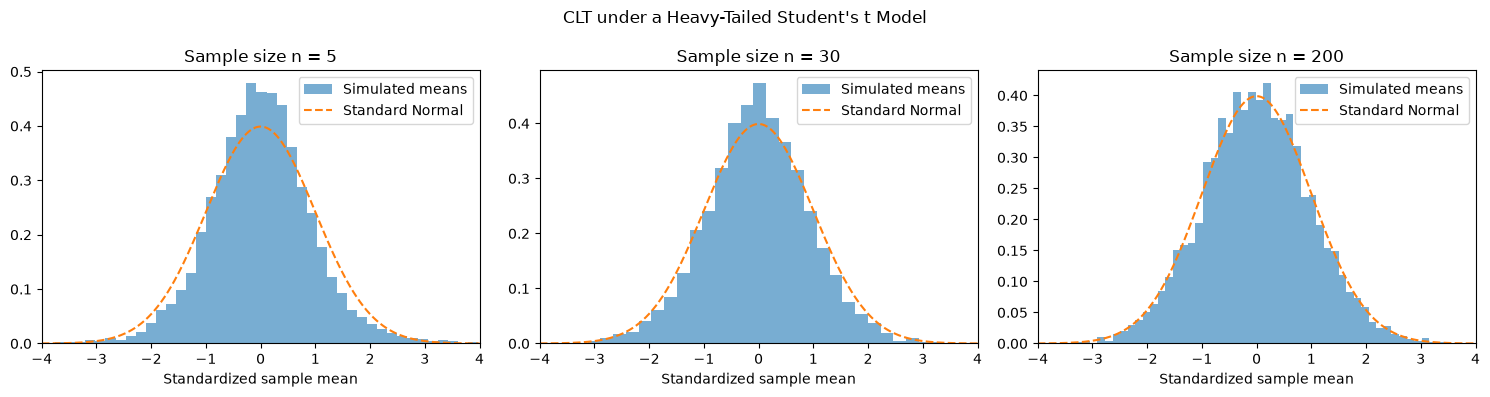

In [20]:

# CLT experiment using heavy-tailed returns

rng = np.random.default_rng(69)

R = 5000
nu = 3

# Match the Student's t variance to ICLN's variance
t_scale = sigma_icln * np.sqrt((nu - 2) / nu)

sample_sizes = [5, 30, 200]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Standard Normal reference curve
x = np.linspace(-4, 4, 400)
normal_pdf = np.exp(-x**2 / 2) / np.sqrt(2 * np.pi)

for n, ax in zip(sample_sizes, axes):

    # Generate R independent groups of n heavy-tailed returns
    draws = (
        mu_icln
        + t_scale * rng.standard_t(df=nu, size=(R, n))
    )

    # Calculate one mean per group
    sample_means = draws.mean(axis=1)

    # Standardize the sample means
    z = (
        (sample_means - mu_icln)
        / (sigma_icln / np.sqrt(n))
    )

    # Plot the sampling distribution
    ax.hist(
        z,
        bins=70,
        density=True,
        alpha=0.6,
        label="Simulated means"
    )

    # Compare against Standard Normal
    ax.plot(
        x,
        normal_pdf,
        linestyle="--",
        label="Standard Normal"
    )

    ax.set_xlim(-4, 4)
    ax.set_title(f"Sample size n = {n}")
    ax.set_xlabel("Standardized sample mean")
    ax.legend()

plt.suptitle("CLT under a Heavy-Tailed Student's t Model")
plt.tight_layout()
plt.show()

In [21]:
from scipy.stats import norm, t

nu = 3
t_scale = sigma_icln * np.sqrt((nu - 2) / nu)

# Probability beyond 3 standard deviations
normal_tail = 2 * norm.sf(3)

student_tail = 2 * t.sf(
    3 * sigma_icln / t_scale,
    df=nu
)

print(f"Normal: {normal_tail:.2%}")
print(f"Student's t: {student_tail:.2%}")

Normal: 0.27%
Student's t: 1.38%


In [22]:
for ticker in ["ICLN", "IXC"]:

    returns = dataset["Return"][ticker].dropna()

    mu = returns.mean()
    sigma = returns.std()

    # Absolute deviation from historical mean
    deviations = np.abs(returns - mu)

    # Count returns beyond three historical SDs
    extreme_days = (deviations > 3 * sigma).sum()

    # Calculate relative frequency
    extreme_frequency = extreme_days / len(returns)

    print(f"{ticker}:")
    print(f"Extreme days: {extreme_days}")
    print(f"Empirical frequency: {extreme_frequency:.2%}")
    print()

ICLN:
Extreme days: 19
Empirical frequency: 1.52%

IXC:
Extreme days: 12
Empirical frequency: 0.96%

